# CDS 303 Final Project – Session 1
## Variable Check and Supplementary Dataset Check
**Team Members:** Seohyun Hong, Sieun Woo, Seoyoung Yun

This notebook supports our Session 1 page. We check:
1. the variables we selected for clustering and classification,
2. the variables we plan to exclude,
3. the data preparation that is needed, and
4. the supplementary dataset (Calendar Data).

We do **not** run clustering or classification, and we do **not** merge the datasets in this session.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings(action = 'ignore')

## 2. Load the Listings Data
We use the New York City detailed listings file from Inside Airbnb (September 14, 2026).

In [2]:
df = pd.read_csv("listings.csv", low_memory = False)
df.shape

(29918, 90)

## 3. Variables in Our Variable-Selection Table
We look only at the variables we discussed on our Session 1 page.

In [3]:
clustering_vars = ['price', 'availability_30', 'availability_365', 'minimum_nights']
classification_vars = ['room_type', 'neighbourhood_group_cleansed', 'calculated_host_listings_count', 'license']
exclude_vars = ['id', 'host_id', 'bathrooms', 'availability_60', 'availability_90']

df[clustering_vars + classification_vars].head()

,price,availability_30,availability_365,minimum_nights,room_type,neighbourhood_group_cleansed,calculated_host_listings_count,license
0,NaN,30,365,30.0,Entire home/apt,Brooklyn,1,NaN
1,$164.55,29,364,31.0,Private room,Queens,1,NaN
2,NaN,30,269,30.0,Private room,Brooklyn,2,NaN
3,NaN,0,0,30.0,Entire home/apt,Manhattan,2,NaN
4,NaN,0,0,80.0,Private room,Brooklyn,1,NaN


In [4]:
df[clustering_vars + classification_vars + exclude_vars].dtypes

price                                 str
availability_30                     int64
availability_365                    int64
minimum_nights                    float64
room_type                             str
neighbourhood_group_cleansed          str
calculated_host_listings_count      int64
license                               str
id                                  int64
host_id                             int64
bathrooms                         float64
availability_60                     int64
availability_90                     int64
dtype: object

`price` is stored as text (object), so we need to change it into numbers.

## 4. Clustering Variables
### 4.1 Convert price into numbers

In [6]:
# Example of the original values
df['price'].dropna().head()

1     $164.55
7     $236.00
8     $143.47
9     $102.97
10    $137.70
Name: price, dtype: str

In [7]:
# Remove "$" and "," and change the type to float
df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[\$,]', '', regex = True), errors = 'coerce')
df[['price', 'price_num']].dropna().head()

,price,price_num
1,$164.55,164.55
7,$236.00,236.00
8,$143.47,143.47
9,$102.97,102.97
10,$137.70,137.70


### 4.2 Missing values in the clustering variables

In [8]:
cols = ['price_num', 'availability_30', 'availability_365', 'minimum_nights']
missing = pd.DataFrame({
    'missing count': df[cols].isna().sum(),
    'missing %': (df[cols].isna().mean() * 100).round(1)
})
missing

,missing count,missing %
price_num,10512,35.1
availability_30,0,0.0
availability_365,0,0.0
minimum_nights,8,0.0


`price` has 10,512 missing values (35.1%). `minimum_nights` has only 8 missing values.

Next, we check **which listings** have a missing price.

In [9]:
# Do listings with 0 available days in the next year have a missing price?
pd.crosstab(df['availability_365'] == 0, df['price_num'].isna(),
            rownames = ['availability_365 == 0'], colnames = ['price missing'])

price missing,False,True
availability_365 == 0,,
False,19397,3503
True,9,7009


In [10]:
pd.crosstab(df['availability_365'] == 0, df['price_num'].isna(),
            rownames = ['availability_365 == 0'], colnames = ['price missing'], normalize = 'index').round(3)

price missing,False,True
availability_365 == 0,,
False,0.847,0.153
True,0.001,0.999


Almost all listings with **0 available days** in the next year have no price.
So the missing prices are not random. They mostly belong to listings that are not open for booking.
We will decide how to handle them in the next session.

### 4.3 Summary statistics

In [11]:
df[['price_num', 'availability_30', 'availability_365', 'minimum_nights']].describe().round(1)

,price_num,availability_30,availability_365,minimum_nights
count,19406.0,29918.0,29918.0,29910.0
mean,310.2,9.4,188.8,26.8
std,574.1,11.7,140.5,28.5
min,17.7,0.0,0.0,1.0
25%,103.7,0.0,14.0,30.0
50%,182.4,2.0,227.0,30.0
75%,337.0,19.0,323.0,30.0
max,31537.8,30.0,365.0,1124.0


The ranges are very different (for example, 0–30 days vs. 0–365 days vs. prices in dollars). This is why we plan to use `StandardScaler`.

### 4.4 Distributions

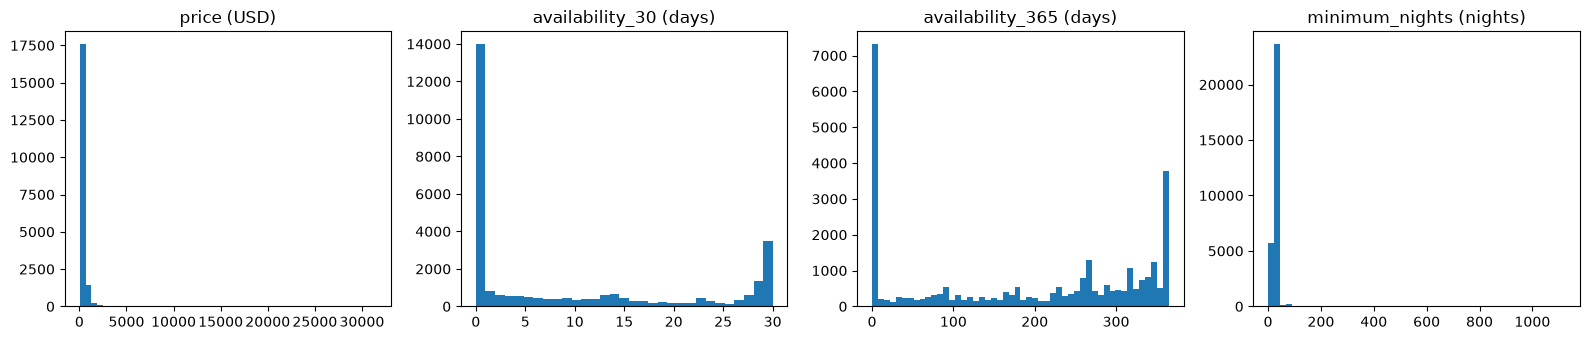

In [12]:
fig, axes = plt.subplots(1, 4, figsize = (16, 3.5))
axes[0].hist(df['price_num'].dropna(), bins = 50)
axes[0].set_title('price (USD)')
axes[1].hist(df['availability_30'], bins = 31)
axes[1].set_title('availability_30 (days)')
axes[2].hist(df['availability_365'], bins = 50)
axes[2].set_title('availability_365 (days)')
axes[3].hist(df['minimum_nights'].dropna(), bins = 50)
axes[3].set_title('minimum_nights (nights)')
plt.tight_layout()
plt.show()

### 4.5 Unusual values

In [13]:
# Very high prices
print("Highest prices:")
print(df['price_num'].sort_values(ascending = False).head(5))
print()
print("99th percentile of price:", df['price_num'].quantile(0.99))
print("Listings above $2,000:", (df['price_num'] > 2000).sum())

Highest prices:
4684     31537.82
10299    16630.00
9946     16630.00
9747     12279.07
2455     12217.60
Name: price_num, dtype: float64

99th percentile of price: 2000.0
Listings above $2,000: 194


In [14]:
# Minimum-night requirements
print("Most common minimum_nights values:")
print(df['minimum_nights'].value_counts().head(5))
print()
print("Share of listings with minimum_nights >= 30:", round((df['minimum_nights'] >= 30).mean(), 3))
print("Listings with minimum_nights > 365:", (df['minimum_nights'] > 365).sum())

Most common minimum_nights values:
minimum_nights
30.0    23222
1.0      4102
2.0       883
3.0       435
31.0      311
Name: count, dtype: int64

Share of listings with minimum_nights >= 30: 0.807
Listings with minimum_nights > 365: 16


Most listings require at least **30 nights**. Very high prices and very long minimum stays will be checked again before clustering.

### 4.6 Relationship between the two availability variables
On our page we said that `availability_30` and `availability_365` may have similar information. We check their correlation.

Correlation: 0.55


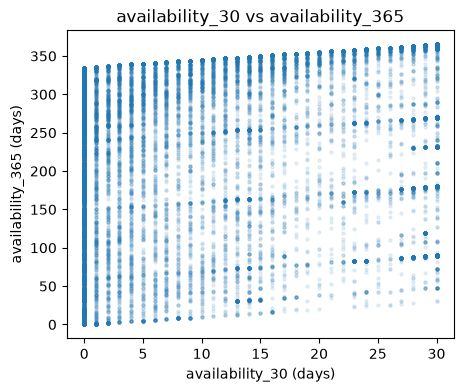

In [15]:
print("Correlation:", round(df['availability_30'].corr(df['availability_365']), 2))

plt.figure(figsize = (5, 4))
plt.scatter(df['availability_30'], df['availability_365'], alpha = 0.1, s = 5)
plt.xlabel('availability_30 (days)')
plt.ylabel('availability_365 (days)')
plt.title('availability_30 vs availability_365')
plt.show()

The correlation is moderate (0.55), not very high, so the two variables give different information (short-term vs. long-term availability). We keep both for now.

## 5. Classification Variables

In [16]:
df['room_type'].value_counts()

room_type
Entire home/apt    16410
Private room       12853
Hotel room           463
Shared room          192
Name: count, dtype: int64

In [17]:
df['neighbourhood_group_cleansed'].value_counts()

neighbourhood_group_cleansed
Manhattan        13681
Brooklyn         10290
Queens            4637
Bronx              989
Staten Island      321
Name: count, dtype: int64

In [18]:
df['calculated_host_listings_count'].describe().round(1)

count    29918.0
mean        51.2
std        159.2
min          1.0
25%          1.0
50%          2.0
75%         11.0
max        889.0
Name: calculated_host_listings_count, dtype: float64

Most hosts have only a few listings, but some hosts have hundreds. This variable is very skewed.

### 5.1 Create `license_status`
The `license` column contains a registration number, the word "Exempt", or nothing.
We do **not** assume that a missing value means the listing is unlicensed, so we call it "not reported".

In [19]:
df['license'].value_counts().head(5)

license
Exempt                2877
OSE-STRREG-0001957       6
OSE-STRREG-0001246       5
OSE-STRREG-0000670       4
OSE-STRREG-0000451       4
Name: count, dtype: int64

In [20]:
lic = df['license'].fillna('')
df['license_status'] = np.where(lic.str.startswith('OSE-STRREG'), 'registered',
                       np.where(lic.str.lower().str.contains('exempt'), 'exempt', 'not reported'))
df['license_status'].value_counts()

license_status
not reported    24810
exempt           2877
registered       2231
Name: count, dtype: int64

### 5.2 Categorical encoding (example)
We will use dummy variables for categorical data such as room type and borough. This is only an example; we do not save it.

In [21]:
pd.get_dummies(df[['room_type', 'neighbourhood_group_cleansed']]).head()

,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room,neighbourhood_group_cleansed_Bronx,neighbourhood_group_cleansed_Brooklyn,neighbourhood_group_cleansed_Manhattan,neighbourhood_group_cleansed_Queens,neighbourhood_group_cleansed_Staten Island
0,True,False,False,False,False,True,False,False,False
1,False,False,True,False,False,False,False,True,False
2,False,False,True,False,False,True,False,False,False
3,True,False,False,False,False,False,True,False,False
4,False,False,True,False,False,True,False,False,False


## 6. Variables to Exclude

In [22]:
print("id unique for each listing:", df['id'].is_unique)
print("Number of different host_id values:", df['host_id'].nunique())

id unique for each listing: True
Number of different host_id values: 16148


`id` and `host_id` are identification numbers. They do not describe a listing, but we keep `id` to connect the datasets later.

In [23]:
print("Missing values in bathrooms:", df['bathrooms'].isna().sum(), "out of", len(df))

Missing values in bathrooms: 29918 out of 29918


`bathrooms` is completely missing, so we exclude it.

In [24]:
df[['availability_30', 'availability_60', 'availability_90', 'availability_365']].corr().round(2)

,availability_30,availability_60,availability_90,availability_365
availability_30,1.00,0.95,0.88,0.55
availability_60,0.95,1.00,0.97,0.64
availability_90,0.88,0.97,1.00,0.70
availability_365,0.55,0.64,0.70,1.00


`availability_60` and `availability_90` are very highly correlated with `availability_30` (0.95 and 0.88), so they repeat the same information. We exclude them.

## 7. Supplementary Dataset: Calendar Data
We load the New York City calendar file from Inside Airbnb to check its columns. We do **not** merge it yet.

In [25]:
cal = pd.read_csv("calendar.csv")
print(cal.shape)
cal.head()

(10920077, 5)


,listing_id,date,available,minimum_nights,maximum_nights
0,23545,2026-09-15,f,30,1125
1,23545,2026-09-16,f,30,1125
2,23545,2026-09-17,f,30,1125
3,23545,2026-09-18,f,30,1125
4,23545,2026-09-19,f,30,1125


In [26]:
cal.columns.tolist()

['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']

**Note:** This calendar file has `listing_id`, `date`, `available`, `minimum_nights`, and `maximum_nights`.
It does **not** have a `price` column. So we can use it to study availability by date, but not daily price changes.

In [27]:
print("Date range:", cal['date'].min(), "to", cal['date'].max())
print("Number of listings in calendar:", cal['listing_id'].nunique())
print()
print("Records per listing:")
print(cal.groupby('listing_id').size().describe().round(1))

Date range: 2026-09-14 to 2027-09-14
Number of listings in calendar: 29918

Records per listing:
count    29918.0
mean       365.0
std          0.0
min        365.0
25%        365.0
50%        365.0
75%        365.0
max        366.0
dtype: float64


In [28]:
cal['available'].value_counts()

available
t    5651942
f    5268135
Name: count, dtype: int64

### 7.1 Can we connect the two datasets?
The Listings Data has `id` and the Calendar Data has `listing_id`.

In [29]:
listing_ids = set(df['id'])
calendar_ids = set(cal['listing_id'])
print("Listings found in calendar:", len(listing_ids & calendar_ids), "out of", len(listing_ids))

Listings found in calendar: 29918 out of 29918


Every listing appears in the calendar, and each listing has about 365 calendar records.
So we must **summarize the calendar for each listing first** (for example, the share of available days), and then merge it with the Listings Data in the next session.

An unavailable day can mean a booking **or** a date blocked by the host, so calendar availability is not an exact booking rate.

## 8. Summary
- **Clustering variables:** `price`, `availability_30`, `availability_365`, `minimum_nights`
- **Classification variables:** `room_type`, borough, `calculated_host_listings_count`, `license_status`
- **Excluded:** `id` (kept only for merging), `host_id`, `bathrooms` (all missing), `availability_60`, `availability_90` (repeat `availability_30`)
- **Preparation needed:** convert `price` to numbers, handle 10,512 missing prices, check very high prices and long minimum stays, scale with `StandardScaler`, use dummy variables for categories
- **Supplementary dataset:** Calendar Data can be connected by `id` = `listing_id` after summarizing it for each listing. It has no price column.